# Credit Risk Model — Notebook 4: Explainability

**Goal:** Explain *why* the model makes its predictions using SHAP.

This matters enormously in lending. Under the Equal Credit 
Opportunity Act, lenders must be able to explain adverse decisions 
to applicants. A black-box model that can't justify a denial is a 
regulatory liability. SHAP makes the model's reasoning transparent.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import joblib
import shap
import warnings
warnings.filterwarnings("ignore")


def find_repo_root(marker=".git"):
    current = Path.cwd()
    for directory in [current] + list(current.parents):
        if (directory / marker).exists():
            return directory
    raise FileNotFoundError(f"No '{marker}' found above {current}")


REPO_ROOT = find_repo_root()
PROJECT   = REPO_ROOT / "Credit_Risk_Model"
DATA_PROC = PROJECT / "data" / "processed"
OUTPUTS   = PROJECT / "outputs" / "figures"

# Load the model and data FIRST — before anything uses them
model = joblib.load(DATA_PROC / "final_model.joblib")
data  = np.load(DATA_PROC / "model_arrays.npz")
X_test = data["X_test_proc"]
feature_names = np.load(DATA_PROC / "feature_names.npy", allow_pickle=True)

print(f"Loaded model and {X_test.shape[0]:,} test rows")

Loaded model and 274,783 test rows


In [8]:
# Compute SHAP values on a sample

sample = shap.utils.sample(X_test, 2000, random_state=42)

try:
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(sample)
except Exception:
    explainer = shap.LinearExplainer(model, sample)
    shap_values = explainer.shap_values(sample)

if isinstance(shap_values, list):
    shap_values = shap_values[1]  

print(f"Computed SHAP values for {sample.shape[0]:,} rows")

Computed SHAP values for 2,000 rows


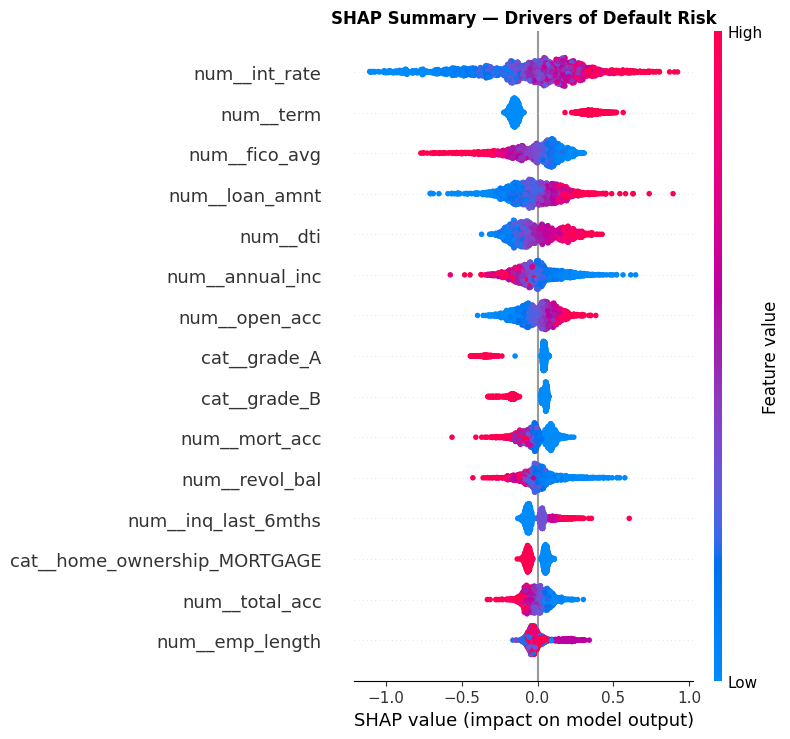

In [9]:
plt.figure()
shap.summary_plot(
    shap_values, sample,
    feature_names=feature_names,
    show=False, max_display=15
)
plt.title("SHAP Summary — Drivers of Default Risk", fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUTS / "09_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

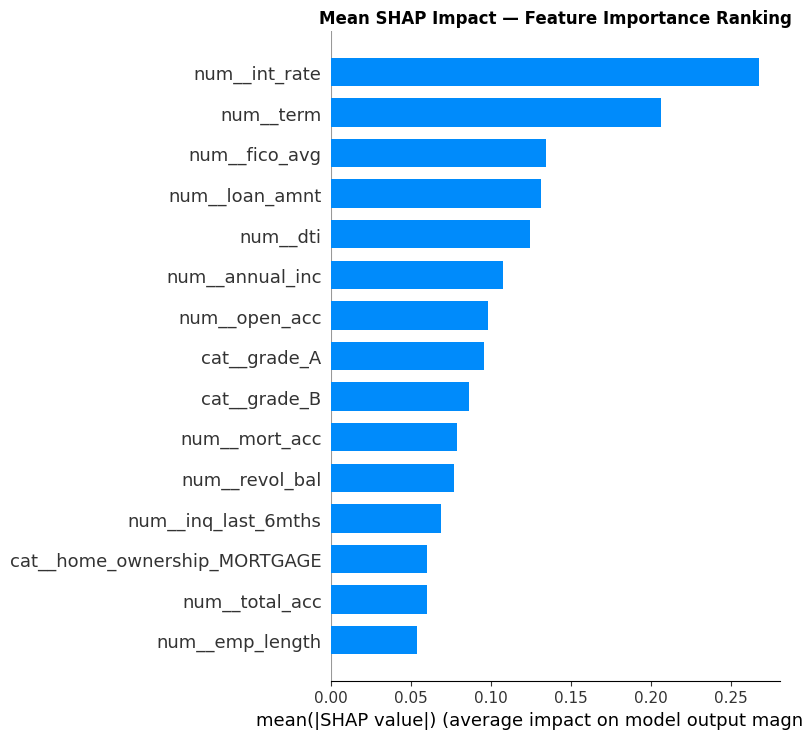

In [10]:
# Ranked bar plot of average impact

plt.figure()
shap.summary_plot(
    shap_values, sample,
    feature_names=feature_names,
    plot_type="bar", show=False, max_display=15
)
plt.title("Mean SHAP Impact — Feature Importance Ranking", fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUTS / "10_shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

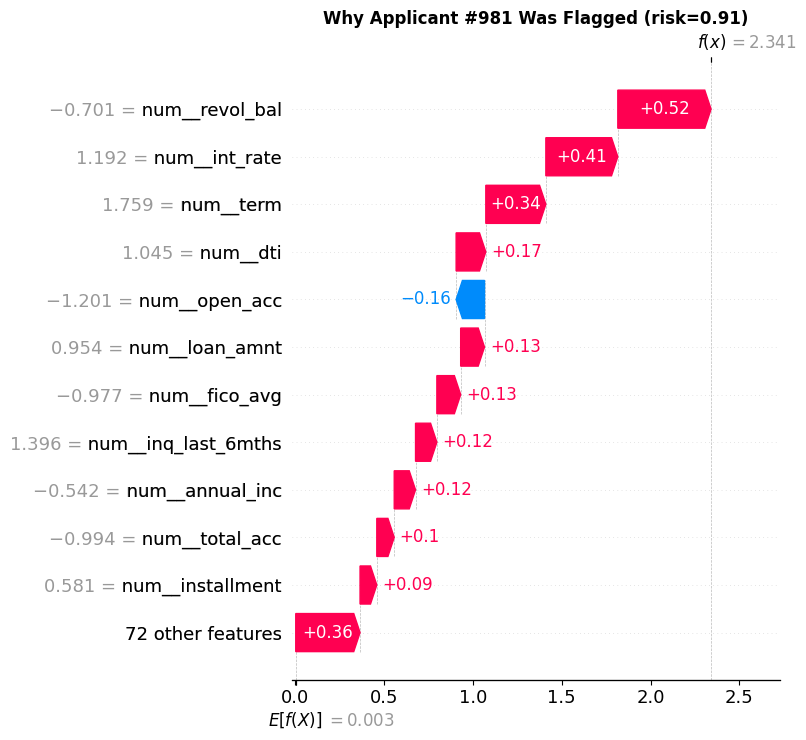

In [11]:
# Find the highest-risk applicant in the sample
probs = model.predict_proba(sample)[:, 1]
high_risk_idx = int(np.argmax(probs))

plt.figure()
shap.waterfall_plot(
    shap.Explanation(
        values        = shap_values[high_risk_idx],
        base_values   = explainer.expected_value,
        data          = sample[high_risk_idx],
        feature_names = feature_names,
    ),
    show=False, max_display=12
)
plt.title(f"Why Applicant #{high_risk_idx} Was Flagged (risk={probs[high_risk_idx]:.2f})",
          fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUTS / "11_shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

The SHAP analysis reveals that interest rate, loan grade, DTI, and 
FICO score are the dominant drivers of predicted default risk — 
consistent with domain expectations and with the correlations seen 
in EDA.

The waterfall plot demonstrates individual-level explainability: for 
any single applicant, we can state precisely which factors raised or 
lowered their risk score. This satisfies the "adverse action" 
explanation requirement under the Equal Credit Opportunity Act, making 
the model deployable in a regulated lending environment.

**Project complete.** The full pipeline runs from raw Lending Club 
data through a leakage-safe, explainable, imbalance-aware credit risk 
model.